# 📘 2.2 Numerical Errors
### Binary values, Floating point precision, Rounding, Trucation, Propagation of Errors.

Explains how values are stored in 1 and 0s (Binary), what this means for storing decimal and non-exact values, how this leads to error that propagate through numerical calculations, and finite approximations to infinite series.

---

### 🎯 Learning Objectives
> By the end of this notebook, you should be able to:
>
> * Recognise the practical limits of measurements and associated uncertainty.
> * Understand how floating point values are stored in memory and how this impacts their precision.
> * Calculate the propagation of uncertainty through mathematical operations
> * Identify the source of truncation and rounding errors.
> * Understand the trade-off between truncation and rounding and how this impact total numerical error.

## 📂 2.2.1 The Pratical Limits of Exact Solutions in Engineering

---

Numerical methods derive from the need for engineers and scientist to solve problems that don't lead themselves to a simple analytical solution. Most of the problem you will faces as an engineering involve complex physics that we don't fully understand or are unable to solve mathematically (e.g. anything that depends on non-linear partial differential equations).

Consider the failure of a beam. To predict this *exactly* (whatever that means), you would need to know the exact loading condition and the precise structure of the material, including any microscopic cracks, residual stresses from machining and local corrosion or pitting. This information is extremely difficult to obtain and will changes during the service life of the beam. How precise do you realistically need to be in your estimation? Will it fail at a load of 10.000001768 N? Through a series of assumptions, it may be possible to reduce the problem to a simple equation for peak stress and from results of material testing, infer a load at which failure might be expected to occur. Unfortunately, as the material, loading or geometry become more complex, we quickly reach the limits of such methods, and are focused to rely on systems of equations which cannot be solved analytically. It is here that engineers must rely on **numerical methods**.

> ### ⚠️ Point of note
> The aim of a numerical methods is to provide a means of answering a practical problem in a numerical form.

Increases in computer speed and the number of FLOPs that can now be readily performed, have opened up solutions that would not have been practical only decades ago. However, there are still practical limit to the sort of industrial problems that can be solved with current computing power, and the level of accuracy that can be achieved, *which is why formula 1 teams still operate expensive wind tunnel facilites* in addition to their Computational Fluid Dynamics (CFD) simulations, and why they don't all arrive at the same optimal design. But there is no doubt that numerical computations will continue to play a growing role in all practical engineering fields. *We don't even have to mention AI here, but those are all numerical computations as well - they're not magic*.

As engineers, we have to be recognise that no data is ever exact. Try going to a workshop and asking a technician to provide a metal plate that is exactly 10 mm thick. Firstly, what you get from a supplies will have a tolerance. It won't be completely flat, and thickness will vary from point to point. Pay more, this may improve, but your 10 mm sheet might still be $10\pm .2$ mm. So, how accurate do you want your plate? You need to specify a tolerance. When you get the plate, and go to check how accurately it was machined, the calipers you use will have a tolerance, and your ability to distinguish between marks on the instrument will be finite.

**Don't think that a digital caliper with a read out of 2 decimal places is necessarily accurate to that level**. Every tool and sensor will have a finite accuracy.

Everytime we perform a numerical calculation, we also have a finite acccuracy to which we are storing our numerical values (how many bits) and introducing other numerical errors. To understand this, it is important to first consider how numbers are stored and approximated by a computer.

## 📂 2.2.2 Numerical Approximations and Floating Point Values

---

There are sitations in which we know a number exactly. For instance, we might know that we have *exactly* **2 apples**, and that if we want to share this evenly between *exactly* 3 people, they will each get *exactly* 2/3 of an apple. But, when we store how much of an apple each person gets, we run into a problem.
$$ \text{Consider } 2/3 \approx 0.66666666666666666666666667$$

We cannot express this fraction exactly as single decimal value. We can only store this value to a finite degree of accurracy, depending on the number of digits we store.

### 🔹 Binary Base-2 Numbers

Ofcourse a computer does not store a number the way we would in base-10. A compute works in binary - base-2. After all, it is just a series of transistor that are either **on** or **off**. Each point in computer memory is a **bit**, which similarly stores, the value **0**, or **1**. A single base-10 digit, 0-9 is therefore represented by one of the 10 binary combinations in Table 2.1. A single decimal digit can therefore occupy upto 4 Bits of memory.

**Table 2.1: Binary Representation of Digits**
| Decimal   |   Binary   |
|-----------|:----------:|
| 0         |    0000    |
| 1         |    0001    |
| 2         |    0010    |
| 3         |    0011    |
| 4         |    0100    |
| 5         |    0101    |
| 6         |    0110    |
| 7         |    0111    |
| 8         |    1000    |
| 9         |    1001    |

Remember, the numbers we typically use are base-10 where each digit holds a value from 0-9. Any value in base-10 is the sum of digits times powers of 10 or our 1s, 10s, 100s columns etc. For example the number $(12)_{10}$ (use subscript to denote the base) is actually
\begin{equation}
(12)_{10} = 1\times10^1 +2\times10^0
\end{equation}
A base-2 number like $(0110)_2$ is similarly the sum of digits times powers of 2, hence 6 is
\begin{equation}
(6)_{10} = (0110)_2 = 0\times2^3 +1\times2^2 + 1\times2^1 + 0\times2^0
\end{equation}
we just consider each column as a power or 2, rather than a power of 10.

> ### ⚠️ Point of note
> Remember - a bit is generally lower case with 'B' reservered for as a Byte. We'll come to this soon.

### 🔹 Integers and the Floating Point

The example above are all **integers**, whole numbers without any decimal. Once we have fractions of a whole we have to include a decimal point. This point can move, for instance if we have 4 digits we can write 0.010 or 100.3. The decimal point can move, or *float*, hence the incomputing terms we refer to this as a **floating point** number or **float** - a terms which generally refers to a 32-bit number, but we'll get to that.

In the example of 2/3, if we truncate this to 6 *significant figures* (i.e. values excluding leading or trailing zeros) we have

$$2/3 \approx 0.666667 \text{ (6 significant figures)}$$

To store this, we need our 6 significant figures, but also need to know where these values are with respect to the decimal point (i.e. where our *floating point* is), and whether the number is positive or negative. To make sense of this, it's easier to consider the value in terms of scientific notation,

$$ 2/3 \approx +6.66667 \times 10^{-1}$$

The largest 6-figure value is 999999 in base-10, but we need to be thinking in binary.

The process for converting a number to binary is fairly simple, and follows a process of dividing a number by 2, finding the nearest integer, storing the remainder (0 or 1), then diving that number by 2 again, until there's nothing left.

This is how we'd convert 999,999 in base-10 to binary:
| | | | | |
|---------|---|---------|---------|-:|
| 999,999|/2 =| 499,999 |remainder| 1|
| 499,999|/2 =| 249,999 |remainder| 1|
| 249,999|/2 =| 124,999 |remainder| 1|
|124,999|/2 = |62,499 |remainder| 1|
| 62,499|/2 = |31,249 |remainder| 1|
| 31,249|/2 = |15,624 |remainder| 1|
| 15,624|/2 = |7,812 |remainder| 0|
| 7,812|/2 = |3,906 |remainder| 0|
| 3,906|/2 = |1,953 |remainder| 0|
| 1,953|/2 = |976 |remainder| 1|
| 976|/2 = |488 |remainder| 0|
| 488|/2 = |244 |remainder| 0|
| 244|/2 = |122 |remainder| 0|
| 122|/2 = |61 |remainder| 0|
| 61|/2 = |30 |remainder| 1|
| 30|/2 = |15 |remainder| 0|
| 15|/2 = |7 |remainder| 1|
| 7|/2 = |3 |remainder| 1|
| 3|/2 = |1 |remainder| 1|
| 1|/2 = |0 |remainder| 1|

The binary number is the remainder, read from bottom to top. In this case, `11110100001000111111`. This may seem like a reversal of the number at first but the same applies to base-10.

> ### 📐 Proof
> Consider how a base-10 number is the remainder or division by 10.
>
>| | | | | |
>|---------|---|---------|---------|-:|
>| 999,999|/10 =| 99,999 |remainder| 9|
>| 99,999|/10 =| 9,999 |remainder| 9|
>| 9,999|/10 =| 999 |remainder| 9|
>| 999|/10 = | 99 |remainder| 9|
>| 99|/2 = |9 |remainder| 9|
>| 9|/10 = | 0 |remainder| 9|
>
>Or if we had 89 in base-10
>
>| | | | | |
>|---------|---|---------|---------|-:|
>| 89|/10 =| 8 |remainder| 9|
>| 8|/10 =| 0 |remainder| 8|
>
>See!

Comming back to $(999999)_{10} = (11110100001000111111)_2$, we see that this  requires 20 bits to store the significant figures. In addition, a float will need sufficient bits to store the exponent `-1`. In this case we only needs two bits to store this exponents (one bit for the sign, `-`, and one for the value `1`). We also need one more bit for the `+` sign on this number. This number requires 23 bits in total, but more would be required if the exponent were $10^{-2}$ or more. It doesn't make much sense to use different memory sizes for each different number - It would be a nightmare.

### 🔹 Standard Structure of a 32-bit (Single Precision) Float

The standard structure of a 32-bit single precision float is shown in Figure 2.3, where a total of 32-bit are used to store significant figures, exponents and their signs. This is similar to the previous example, but done in a less obvious, but really clever and useful way.

<figure>
  <img src="https://drive.google.com/uc?id=1Re3FaViFVArqNf1yBKLQtV2QhJDJwW3p" alt="" style="width:100%;max-width:400px;">
  <figcaption style="text-align: center; font-style: italic; margin-top: 5px;">
    Figure 2.3: Single Precision IEEE 754 Floating Point Standard From https://www.geeksforgeeks.org/c/c-float-and-double/
  </figcaption>
</figure>

The **Mantissa** is the part above that stores the significant figures. This 23-bit Mantissa can represent up to 2^23 or 8,388,608. This suggests that the *Mantissa* of a single precision float can store any 6 decimal digits, but this is done in binary, so a computer isn't storing 6 decimal digit the way we would. This is an important distinction. Let's look at how this is done.

In practice this follows the convention below.

* **Sign**: The 'sign' bit (32nd bit), indicates the sign of the number, "0" for positive and "1" for negative.
* **Exponent**: the 8 exponent bits (24th-31st bit) stores a value from 0 to 255 (i.e. $2^8-1 = 255$). As the exponent can be positive or negative, this stored value is biased, such that a value of 127 represents an exponent of 0, and the stored values 0-255 actually correspond to exponents of -126 to +127. Look closely and you'll realise this correspond to only 253 values - 2 exponents values are reserved for special numbers like NaN and Infinity.
* **Mantissa** (or significand): the Mantissa (bits 1-23) include an implicity leading bit of 1 for all normal numbers, with an implicity 0 used for *subnormal numbers* that are number that would have exponents smaller than the -126 allowed for by the 8-Bit exponent. See https://en.wikipedia.org/wiki/Single-precision_floating-point_format for **more detail than is necessary**, if your are really interested.

> ### ⚠️ Point of note
> We don't have to worry about these special subnormal numbers! For our purposes we can focus on the *normal* numbers. The point of this is *not to force you to memorise this conversion*, but rather to ensure you **understand**  how this structure impacts the **precision** of the values we compute and store.

The structure of a floating point, with the leading bit of 1, follows a normalisation of the format
\begin{equation}
(1.x_1 x_2 x_3...x_{23})_2 \times 2^e
\end{equation}
where $(1.x_1 x_2 x_3...x_{23})_2$ is binary fraction, e.g. 1.0010111 to 23 binary values, which is multipled by a power of 2 with an exponent $e$.

The base-10 value of a number stored as a 32-bit single precision float is given by
\begin{equation}
\mbox{value} = (-1)^{sign}\times 2^{(E-127)}\times\left(1+\sum^{23}_{i=1}+b_{23-i}2^{-i} \right), \tag{2.9}
\end{equation}
where $sign$ is the 0 or 1 from the first bit in figure 2.3, $E$ is base-10 value of the 8 bit binary *exponent*, and $b_j$ is the binary value stored in the j-th bit, with an index of $j=0$ being the binary value of the right most bit value in Figure 2.3. Hence, for $i=1$, $b_{23-i}$ corresponds to $j=22$, the 22nd bit.



### 🧪 Example Binary 32-bit Signed Float to Decimal

Consider the following example where every bit is 1 (other than final exponent, so that we avoid the NAN associated with an exponent of 255). This will correspond to the maximum value that can be stored value, i.e.
<table>
<tr>
<td> <td colspan=1>sign  <td colspan=8> exponent <td colspan=23> mantissa
<tr>
<td> index $j$ <td> 31 <td> 30 <td> 29 <td> 28 <td> 27 <td> 26 <td> 25 <td> 24 <td> 23 <td> 22 <td> 21 <td> 20 <td> 19 <td> 18 <td> 17 <td> 16 <td> 15 <td> 14 <td> 13 <td> 12 <td> 11 <td> 10 <td> 9 <td> 8 <td> 7 <td> 6 <td> 5 <td> 4 <td> 3 <td> 2 <td> 1 <td> 0
<tr>
<td> <td> 1 <td> 1 <td> 1 <td> 1 <td> 1 <td> 1 <td> 1 <td> 1 <td> 0 <td> 1 <td> 1 <td> 1 <td> 1 <td> 1 <td> 1 <td> 1 <td> 1 <td> 1 <td> 1 <td> 1 <td> 1 <td> 1 <td> 1 <td> 1 <td> 1 <td> 1 <td> 1 <td> 1 <td> 1 <td> 1 <td> 1 <td> 1
</table>

* The sign bit is '1' (index $j=31$) hence the number is negative.

* The exponent (bits $j=$30-23) is 1111 1110, which is
\begin{eqnarray}
E &=& b_{j=30}2^{j-23} + b_{j=29}2^{j-23}+b_{j=28}2^{j-23}+b_{j=27}2^{j-23} +b_{j=26}2^{j-23} +b_{j=25}2^{j-23} + b_{j=24}2^{j-23} + b_{j=23}2^{j-23}  \\
&=&  1\times2^7 + 1\times2^6 + 1\times2^5 + 1\times2^4 +1\times2^3 +1\times2^2 + 1\times2^1 + 0\times2^0\\
&=& 254
\end{eqnarray}
Hence the exponent of the decimal number is E-127 = 254-127 = 127.

* The Mantissa (bits $j = 22$ to 0), corresponds to the implicit 1, plus the value of the stored binary value. Rather than writing this out for all 23 bits as we did for the 8-Bit exponent, we can represent this as the summation
\begin{eqnarray}
\mbox{value} &=& 1+\sum^{23}_{i=1}b_{23-i}2^{-i}\\
&=& 1 + b_{22}2^{-1} + b_{21}2^{-2} + b_{20}2^{-3} + ... + b_02^{-23}\\
&=& 1.9999998808
\end{eqnarray}
Combining this with the exponent and sign yields

\begin{eqnarray}
\mbox{value} &=& (-1)^{sign}\times 2^{(E-127)}\times\left(1+\sum^{23}_{i=1}+b_{23-i}2^{-i} \right)\\
&=& -1^1\times 2^{(254-127)}\times(1.9999998808)\\
&\approx& -3.4028235\times 10^{38}
\end{eqnarray}

*Maybe you can ask AI to generate a code to do this conversion for you?*

### 🧪 Example Decimal to Binary 32-bit Signed Float

For completeness, let's look at how we can convert a decimal into a float. First you need to consider the integer part, followed by the fractional part, then add the two parts to get the final result.

Consider the decimal $(16.0625)_{10}$. Convert the integer part '16' to binary as before by dividing by 2 and storing the remainder.

| | | | | |
|---------|---|---------|---------|-:|
| 16|/2 =| 8 |remainder| 0|
| 8|/2 =| 4 |remainder| 0|
| 4|/2 =| 2 |remainder| 0|
| 2|/2 = |1 |remainder| 0|
| 1|/2 = |0 |remainder| 1|

Hence, 16 in base-10 or $(16)_{10}$ is 10000 in binary or $(1 0000)_2$.

> ### ⚠️ Point of note
> We can add the a space between every 4 binary values to help visually break up the number.

Now consider the fractional part $(0.0625)_{10}$. To convert to a binary fraction, we multiply the fractional part by 2, until the fractional part disappears or you reach the maximum number of fractional digits (23 for float 32-Bit).

\begin{equation}
0.0625 \times 2^4 = 1
\end{equation}

In this case, multiplying by 2 four times $(2^4)$ gives us 1 exactly, hence we can exactly present the base-10 fraction 0.0625 as a binary fraction.

> ### ⚠️ Point of note
> Not all decimal fractions can represented as exact binary fractions. For instance, $0.512 \times 2^{23}$ still has a fractional remainder. We'll come back to this in a bit.

We can now convert the fractional part, after multiplying by $2^4$ to binary as we did for the original integer values, i.e.

| | | | | |
|---------|---|---------|---------|-:|
| $0.0625 \times2^4 =1$| $/2 =$| 0 |remainder| 1|

hence $(0.0625\times 2^4)_{10}$ in base-10 is equal to  $(1)_2$ in base-2. Therefore
$$(0.0625)_{10} = (1)_2 / 2^4$$.

Dividing by 2 in base-2 is equivalent to dividing by 10 in base-10, i.e. it moves the decimal point, hence

\begin{equation}
(0.0625)_{10} = (0.0001)_2
\end{equation}

Consider the combination of the integer and fractional parts,
\begin{eqnarray}
(16.0625)_{10} &=& (16)_{10} + (0.0625)_{10} = (10000)_2 + (0.0001)_2\\
(16.0625)_{10} &=& (1\mbox{ }0000.0001)_2
\end{eqnarray}

This 10000.0001 is a binary representation of 16.0625, but does not follow the conventions of a 32-Bit Float. Recalling that floating point numbers use the following normalisation,
\begin{equation}
(1.x_1 x_2 x_3...x_{23})_2 \times 2^e
\end{equation}
the *normalised* binary representation of $(16.0625)_{10}$ is
\begin{equation}
(16.0625)_{10}=(1.0000\mbox{ }0001)_2 \times 2^4
\end{equation}


From this we can see that the exponent is $e=4$, which stored in the bias when exponent form of a standard float (remember we need to account for the sign of the exponent) becomes
\begin{equation}
(127+4)_{10}=(131)_{10}.
\end{equation}

The exponent also needs to be stored in binary, so converting $(131)_{10}$ to binary,

| | | | | |
|---------|---|---------|---------|-:|
| 131|/2 =| 65 |remainder| 1|
| 65|/2 =| 32 |remainder| 1|
| 32|/2 =| 16 |remainder| 0|
| 16|/2 =| 8 |remainder| 0|
| 8|/2 =| 4 |remainder| 0|
| 4|/2 =| 2 |remainder| 0|
| 2|/2 =| 1 |remainder| 0|
| 1|/2 =| 0 |remainder| 1|

the biased binary exponent becomes
\begin{equation}
(127+4)_{10}=(131)_{10}=(1000\mbox{ }0011)_2
\end{equation}

Recalling that the sign is zero for a positive number, and that the exponent `1000 0011` has to occupy 8-bits we see we that this value will already fill out this bits.

When it comes to the *mantissa*, we need to remember that the one before the `.` in our required value opf `1.0000 0001` is already implied. The full 23-bit *mantissa* is everying after the `.`, i.e. `0000 0001 0000 0000 0000 000`. The additional bits need to be padded out with zeros. The full binary floating point representation becomes

<table>
<tr>
<td> <td colspan=1>sign  <td colspan=8> exponent <td colspan=23> mantissa
<tr>
<td> index $j$ <td> 31 <td> 30 <td> 29 <td> 28 <td> 27 <td> 26 <td> 25 <td> 24 <td> 23 <td> 22 <td> 21 <td> 20 <td> 19 <td> 18 <td> 17 <td> 16 <td> 15 <td> 14 <td> 13 <td> 12 <td> 11 <td> 10 <td> 9 <td> 8 <td> 7 <td> 6 <td> 5 <td> 4 <td> 3 <td> 2 <td> 1 <td> 0
<tr>
<td> <td> 0 <td> 1 <td> 0 <td> 0 <td> 0 <td> 0 <td> 0 <td> 1 <td> 1 <td> 0 <td> 0 <td> 0 <td> 0 <td> 0 <td> 0 <td> 0 <td> 1 <td> 0 <td> 0 <td> 0 <td> 0 <td> 0 <td> 0 <td> 0 <td> 0 <td> 0 <td> 0 <td> 0 <td> 0 <td> 0 <td> 0 <td> 0
</table>

In this case, the representation is *exact* since $(0.0625)_{10}$ can be precicely represent as a binary fraction, but this is the exeception rather than the rule.

Graphically, you can get a better idea of how this works by playing around with a converter like the one found here: https://www.h-schmidt.net/FloatConverter/IEEE754.html or analytical through the following example

**The Important Point here is that accuracy of any given floating number is finite**.

In [ ]:
# @title  🎥 Video - Understanding the 32-bit Floating Point Number Convention through a Visual Converter (9:24)
from IPython.display import IFrame
IFrame(src="https://drive.google.com/file/d/1sG2zaDgdCvBXMJhkkW3rfgn6NRa2aROW/preview", width="640", height="360")

## 📂 2.2.3 The Precision of Floating Point Numbers

---

So why did we bother going through these examples of decimal to floating point binary and vice versa? Surely engineers don't need to know this? Well, we did it for two reasons. This is something you should be able to do and may have to do to diagnose issues with digital pressure sensors or temperature sensors who might send values in binary, but more importantly, it highlights the finite accurracy of these values. The value $(16.0625)_{10}$, in the previous example was prefectly represented, but this is only because 1/0.0625 = 16 is a power of 2.   

 When using non-exact numbers, we are forced to rely on a floating point numerical approximation to that value, but how accurate are these approximations?

 Consider the binary 32-bit signed floating point representation of $(1)_{10}$. I'll save you the math, but this is nice and easy. Since it has no fractional part the *mantissa* is all zeros, so we only have to worry about the exponent, i.e.
 \begin{equation}
(1)_{10} = (1)_2 \times 2^0
 \end{equation}
 but since the exponent is biased, $E = 0 + 127$, the stored value $E$ is 127,  hence the biased exponent is
 \begin{equation}
(127+0)_{10}=(127)_{10}=(111\mbox{ }1111)_2.
\end{equation}
 Hence $(1)_{10}$ is stored in a 32-bit float as
<table>
<tr>
<td> <td colspan=1>sign  <td colspan=8> exponent <td colspan=23> mantissa
<tr>
<td> index $j$ <td> 31 <td> 30 <td> 29 <td> 28 <td> 27 <td> 26 <td> 25 <td> 24 <td> 23 <td> 22 <td> 21 <td> 20 <td> 19 <td> 18 <td> 17 <td> 16 <td> 15 <td> 14 <td> 13 <td> 12 <td> 11 <td> 10 <td> 9 <td> 8 <td> 7 <td> 6 <td> 5 <td> 4 <td> 3 <td> 2 <td> 1 <td> 0
<tr>
<td> <td> 0 <td> 0 <td> 1 <td> 1 <td> 1 <td> 1 <td> 1 <td> 1 <td> 1 <td> 0 <td> 0 <td> 0 <td> 0 <td> 0 <td> 0 <td> 0 <td> 0 <td> 0 <td> 0 <td> 0 <td> 0 <td> 0 <td> 0 <td> 0 <td> 0 <td> 0 <td> 0 <td> 0 <td> 0 <td> 0 <td> 0 <td> 0
</table>

Here comes the important 'bit', so to speak. What is the closest number we can store near to 1.0

The closest value to this is this number plus the smallest bit, i.e.

<table>
<tr>
<td> <td colspan=1>sign  <td colspan=8> exponent <td colspan=23> mantissa
<tr>
<td> index $j$ <td> 31 <td> 30 <td> 29 <td> 28 <td> 27 <td> 26 <td> 25 <td> 24 <td> 23 <td> 22 <td> 21 <td> 20 <td> 19 <td> 18 <td> 17 <td> 16 <td> 15 <td> 14 <td> 13 <td> 12 <td> 11 <td> 10 <td> 9 <td> 8 <td> 7 <td> 6 <td> 5 <td> 4 <td> 3 <td> 2 <td> 1 <td> 0
<tr>
<td> <td> 0 <td> 0 <td> 1 <td> 1 <td> 1 <td> 1 <td> 1 <td> 1 <td> 1 <td> 0 <td> 0 <td> 0 <td> 0 <td> 0 <td> 0 <td> 0 <td> 0 <td> 0 <td> 0 <td> 0 <td> 0 <td> 0 <td> 0 <td> 0 <td> 0 <td> 0 <td> 0 <td> 0 <td> 0 <td> 0 <td> 0 <td> 1
</table>

This corresponds to a decimal value of `1.00000011920928955078125`, which means that we can represent any values between `1` and `1.00000011920928955078125`. Hence the precision with which we can represent any number in this range is approximately 1e07. This the *machine precision*.

>### 📖 Definition
> **Machine Precision**: is the upper bound on the relative rounding error introduced by floating-point arithmetic. It quantifies the finest resolution the machine's number system can represent.
> In practice this is often defined as the difference between 1 bit more than 1, and 1, e.g.
>$$\varepsilon = \text{nextfloat}(1) - 1$$
> Exactly what we calculated above.


What if our number is 2 or 10, or 1000? Consider the equation that converts this binary form to decimal
\begin{equation}
\mbox{value} = (-1)^{sign}\times 2^{(E-127)}\times\left(1+\sum^{23}_{i=1}+b_{23-i}2^{-i} \right).
\end{equation}
We see that for a given exponent, $e=E-127$, the value $1\times 2^e$ will have an all zero mantissa, such that the next number will have zeros in all but $b_0$ binary bit such that the next smallest increments is always $\left(1+2^{-23}\right)\times 2^e$. This leads to a numerical precision that varies with the value of the exponent as follows.

| (E-127) = e| $1 \times 2^e$| next floating value | precision limit |
|-|--|--|--|
-126 | $(1.17549435082 \times 10^{-38})_{10}$ | $(1.17549449095 \times 10^{-38})_{10}$ | $(1.40129846432\times 10^{-45})_{10}$ |
-62 | $(2.16840434497 \times 10^{-19})_{10}$ | $(2.16840460346 \times 10^{-19})_{10}$ | $(2.58493941423\times 10^{-26})_{10}$ |
-31 | $(4.65661287307739 \times 10^{-10})_{10}$ | $(4.65661287416159 \times 10^{-10})_{10}$ | $(5.55111512313\times 10^{-17})_{10}$ |
-16 | $(1.52587890625 \times 10^{-5})_{10}$ | $(1.52587908814894 \times 10^{-10})_{10}$ | $(1.81898940355 \times 10^{-12})_{10}$
-8 | $(0.0039062500000)_{10}$ | $(0.0039025046566)_{10}$ | $(4.65661287307739 \times 10^{-10})_{10}$
-4 | $(0.0625)_{10}$ | $(0.0625000074506)_{10}$ | $(7.45058059692383 \times 10^{-9})_{10}$
-2 | $(0.25)_{10}$ | $(0.250000029802)_{10}$ | $(2.98023223876953 \times 10^{-8})_{10}$
-1 | $(0.5)_{10}$ | $(0.500000059605)_{10}$ | $(5.96046447753906 \times 10^{-8})_{10}$
0 | $(1)_{10}$ | $(1.00000011921)_{10}$ | $(1.19209289550781 \times 10^{-7})_{10}$
1 | $(2)_{10}$ | $(2.00000023842)_{10}$ | $(2.38418579101562 \times 10^{-7})_{10}$
2 | $(4)_{10}$ | $(4.00000047684)_{10}$ | $(4.76837158203125 \times 10^{-7})_{10}$
... | | | |
127 | $(1.17014118346 \times 10^{38})_{10}$ | $(1.170141203743 \times 10^{38})_{10}$ | $(2.0282409604\times 10^{31})_{10}$ |

> ### ⚠️ Point of note
> Importantly, the structure of a binary float ensures that the precision and numerical error is not fixed at say at an absolute $10^{-7}$, but is instead proportional to the value, such that it is about $10^{-7}$ smaller the value or about $1\times10^{-5}$ %.

**That's why the structure of the floating point number seems unnecesarily complex!**

## 📂 2.2.4 The Implication of Numerical Approximations

---

If you take one thing from the previous section, it should be that most numbers you will encounter as an engineer will be *approximate numbers*, measured and stored as a finite number of *significant figures*.

> ### ⚠️ Point of note
> If your colleagues measure an angle as 42.5 degrees and asks you to convert it to radians, do NOT quote the answer as 0.741764932098 rad! Is your answer really accurate to more than 0.0005 radians?

There is little point in keeping values beyond the number of significant figures in your original data. If your colleague measured the angle using a protractor with marks at 1 deg intervals, then the best they can do is measure it to half an interval, or 0.5 degrees. This corresponds to approximately 0.009 radians. If we consider that the original angle is accurate to 3 *significant figures* then in radians we would expect this to be similary accurate to 3 *significant figures*, i.e. and answer of 0.742, having rounded up to the nearest significant figure.

<figure>
  <img src="https://drive.google.com/uc?id=11DsyJcvOXtUTDj3cqsUE4idkx4UGgIUu" alt="" style="width:100%;max-width:400px;">
  <figcaption style="text-align: center; font-style: italic; margin-top: 5px;">
    Figure 2.4: A protractor used to measure an angle. Note the finest marks are at 1 degree intervals. Can you really measure anything better than 0.5 a degree with this tool? From https://www.istockphoto.com/
  </figcaption>
</figure>

To formalise this rounding off operation, to **round-off** to *n* significant figures:
1. Discard all digits to the right of the *n*th digit.
2. If the left most discarded number is:\
    a. less than half a unit if the nth place (in base 10, less than 5), leave the nth unit unchanged\
    b. greater than half the unit in the nth place (in base 10, greater than 5), increase the nth unit by 1.\
    c. exactly half a unit in the nth place (in base 10, exactly 5), increase the nth unit by 1 if it is odd, otherwise leave it unchanged.






Let's Ask AI to produce a Mermaid chart of this logic operation.

>### 🗣️ AI Prompts
> Provide a Mermaid flow chart for the following round-off operation: to round-off to n significant figures:
Discard all digits to the right of the nth digit.
If the left most discarded number is:
a. less than half a unit if the nth place (in base 10, less than 5), leave the nth unit unchanged
b. greater than half the unit in the nth place (in base 10, greater than 5), increase the nth unit by 1.
c. exactly half a unit in the nth place (in base 10, exactly 5), increase the nth unit by 1 if it is odd, otherwise leave it unchanged.

>### 🧠 AI Output
>```
>flowchart TD
>    A[Start] --> B{Discard all digits to the right of the nth digit};
>    B --> C{Left most discarded number};
>
>    C -- "< half unit (e.g., < 5)" --> D[Leave nth unit unchanged];
>    C -- "> half unit (e.g., > 5)" --> E[Increase nth unit by 1];
>    C -- "= half unit (e.g., = 5)" --> F{Is nth unit odd?};
>
>    F -- "Yes" --> E;
>    F -- "No" --> D;
>
>    D --> G[End];
>    E --> G[End];
>```

There are so issue with the AI output here. For instance, if we follow the convension this should start with rounded node, and the second node is not a conditional statement and should not be a diamond. We could tell the AI to correct this or just modify it ourself - probably faster.

Let's wrap our modified version into the Colab-print codes we use in Week 1.

In [ ]:
# @title Flow Chart for Matrix Multiplication
# Try to access the colab_print tool
try: from colab_print import mermaid
except:
  # access failed to install it and try again
  !pip install colab-print
  from colab_print import mermaid

# run the mermaid tool -
# NOTE: you can't include # comments inside the mermaid script
mermaid('''
flowchart TD
    A(Start) --> B[Discard all digits to the right of the nth digit];
    B --> C{If left most discarded number};
    C -- "< half unit (e.g., < 5)" --> D[Leave nth unit unchanged];
    C -- "> half unit (e.g., > 5)" --> E[Increase nth unit by 1];
    C -- "= half unit (e.g., = 5)" --> F{Is nth unit odd?};
    F -- "Yes" --> E;
    F -- "No" --> D;
    D --> G(End);
    E --> G(End);
''',theme='neutral')

### 🧪 Rounding Example

Round the following values to 3 *significant figures*:

\begin{eqnarray}
&7.893 &\mbox{ to } &7.89\\
&12.865 &\mbox{ to } &12.9\\
&6.4356 &\mbox{ to } &6.44\\
&3.567 &\mbox{ to } &3.57\\
&84767 &\mbox{ to } &84800\\
&5.8254 &\mbox{ to } &5.82
\end{eqnarray}

## 📂 2.2.5 Numerical Errors

---

The fact that measurements have finite accuracy, compounded by our ability to only store a number to finite precision, leads to a number of **numerical errors** which we will define as:

> ### 📖 Definition
> * **Inherent errors**: errors that are present in the input data due to approximations or limited precision of input data.
>
>* **Rounding errors**: errors that arise during a computation due to finite numerical precision and the rounding of numerical values at various points during a computation. These can be reduced by
>
>    * avoiding subtraction of nearly equal numbers, or division by small numbers
>    * retaining at least one more significant figure than the input at all stages of the calculation.
>
>* **Truncation errors**: errors that occur in algorithms due to a finite approximation to a mathematical series (we'll come back to this).

Each of these can be expressed as *absolute, relative or similarly a percentage error*.

> ### 📖 Definition
> * **Absolute error**: is the difference between the actual quantity $X$, and the calculated or approximated value $X'$, i.e. $|X-X'|$. This has units the same as $X$.
>
>* **Relative error**: is the absolute error normalised by the actual quantity, i.e. $\frac{|X-X'|}{X}$, which is non-dimensional.
>
>* **Percentage error**: is relative area expressed as a percentage, i.e. $100\frac{|X-X'|}{X}$.

If a quantity is correct to 3 signficant figures, then the absolute error is 0.5 times the nth position.

### 🧪 Example of Rounding Error in Floating Point Calculations

Consider what happends when we subtract two very similar floating point number, compared with the same subtraction of integer values.

> ### 🧾 Instructions
> * Run the cell below and note the output. In both cases the difference between 100,000,001 and 100,000,000 should be one. Is it?

In [ ]:
""" Example of Rounding errors when subtracting similar values """
import numpy as np
a = np.float32(100000001)
b = np.float32(100000000)
print("as float32 100000001 - 100000000 = ",a-b)

a = np.int32(100000001)
b = np.int32(100000000)
print("as int32 100000001 - 100000000 = ",a-b)


as float32 100000001 - 100000000 =  0.0
as int32 100000001 - 100000000 =  1


### 🧪 Example of Absolute and Relative Errors

Consider the value
$$X=2.346$$
If this were to be rounded to 3 *significant figures* the approximation would be
$$X'=2.35$$
The magnitude of absolute error would be
$$|X-X'| = |2.346 - 2.35| = 0.004$$
This calculation requires knowledge of the True value, $X$, but in the absense of this we would approximate the absolute error as
$\pm 0.005$.

 This is the uncertainity when the true value is not known. In practice this mean that the true value is somewhere in the range from 2.35-0.005 to 2.35+0.005 or between 2.345 and 2.355. Note, this corresponds to the range of values that would round to 2.35.

 We can then express our estimate of $X$ as
 $$X = 2.35 \pm 0.005$$

### 🔹 Estimating Errors for Rounded Numbers


For a rounded number of the form
$$ 0.\#\#\#\# \times 10^n$$
 where $n$ is the exponent and $k$ is the number of significant figures after rounding, the following expressions can be used to estimate the absolute and relative errors;

\begin{equation}
|X-X'| < \frac{1}{2}\times10^{n-k}, \tag{2.10}
\end{equation}
and
\begin{equation}
\frac{|X-X'|}{X} < \frac{1}{2}\times10^{1-k}. \tag{2.11}
\end{equation}

### 🧪 Estimate the Absolute and Relative Error of a Rounded Value

Take for example, $X=20.353$, rounded to 4 significant figures, which becomes $X'=20.35$. The actually absolute and relative errors are:
\begin{eqnarray}
|X-X'| &=& |20.353-20.35| &=& 0.003\\
\frac{|X-X'|}{X} &=& \frac{0.003}{20.353} &\approx& 0.000147
\end{eqnarray}
Using the equations above, had we not know the true value, we would arrive at the following approximations for the absolute and relative errors.
Noting that $X'$ can be expressed as $X' = 0.2035 \times 10^2$, so $n = 2$, $k=4$ hence the absolute error is at most
\begin{eqnarray}
|X-X'| &<& \frac{1}{2}\times10^{2-4} &<& 0.005\\
\frac{|X-X'|}{X} &<& \frac{1}{2}\times10^{1-4} &<& 0.0005\\
\end{eqnarray}
In both cases we see that the true error are of the same order, but within the bounds of these values.




## 📂 2.2.6 Propagation of Errors

---

Now that we have a better sense of the error associated with a given value, for example the *inherent error* on input data that is feed into an algorithm and the limited precision with which a float can represent a given value, we need to consider how these error behaves when added to or multipled by another value with its own error or finite accurracy.

Let's start by considering absolute error in addition, subtraction, multiplication and division of values exact values $X$ and $Y$, which are are represented by finite precision values $X'$ and $Y'$ such that the *inherent* absolute errors are.
\begin{eqnarray}
\epsilon_{aX} &=& X-X'\\
\epsilon_{aY} &=& Y-Y'
\end{eqnarray}
    

### 📐 Absolute Errors in Addition

Representing X, Y in terms of their respective errors,
$$ X = X' + \epsilon_{aX}, \text{ }Y = Y' + \epsilon_{aY}$$

 we can expresses the addition of the true values of $X,Y$ as
    \begin{eqnarray}
      X+Y &=& (X'+\epsilon_{aX}) + (Y'+\epsilon_{aY}),\\
      X+Y &=& X'+Y' + (\epsilon_{aX} + \epsilon_{aY}),\\
    \end{eqnarray}
    hence, we can represent the difference between the sum of the true values and the sum of their approximations, and hence the error in the *addition* as
     \begin{eqnarray}
      |(X+Y) - (X'+Y')| = |\epsilon_{aX} + \epsilon_{aY}|.
    \end{eqnarray}
This means that the magnitude of the difference between the sum without error and with inherent errors is equal to the magnitude of the sum of the error in each of the inputs.

In most cases the inherent error is random and hence could be positive or negative. Sometime these error will cancel each other out and others they will add to each other. Given we won't know the actual error, we have to consider either the worst possible case, or the most statstically likely situation.

This leads to two cases of error propagation and potentially, the cause of alot of confusion. The first of these is the more conservative approach.
    
* **Worst Case Error**: assumes that the error is the the sum of the magnitude of both the individual errors, i.e.
\begin{eqnarray}
    |(X+Y) - (X'+Y')| = |\epsilon_{aX} + \epsilon_{aY}| \le |\epsilon_{aX}| + |\epsilon_{aY}|.\tag{2.12}
\end{eqnarray}
This assume error can't cancel each other out in any way.
    
* **Quadrature - Statistical Case**: focuses on the random error in each variable. Consider what happends when ew square a value then take the squareroot. We end up with a value that is equivalent to the magnitude, hence we can express the magnitude of the sum of the errors as
\begin{eqnarray}
       |\epsilon_{aX} + \epsilon_{aY}| &=& \sqrt{\left(\epsilon_{aX} + \epsilon_{aY}\right)^2} = \sqrt{\epsilon^2_{aX} + \epsilon^2_{aY} + 2\epsilon_{aX}\epsilon_{aY}} \tag{2.13}
    \end{eqnarray}
The squares of the errors are independent of each other, however, the product of the error in X and the error in Y are not. The produce of these error would be different if they were both negative at the same time, or if one was negative and one positive. In most cases we would assume that the error in X, is random and uncorrelated with the error in Y. In such cases, the product of the errors would be zero, i.e. $\epsilon_{aX}\epsilon_{aY}=0$, on average and the error can be hence be approximated as,
     \begin{eqnarray}
      |(X+Y) - (X'+Y')| = |\epsilon_{aX} + \epsilon_{aY}| = \sqrt{\epsilon^2_{aX} + \epsilon^2_{aY}} \tag{2.14}
    \end{eqnarray}

>### ⚠️ Point of note
>You will find both equations 2.13 and 2.14 quoted as solutions for the progagation of error in the addition of terms in various textbook or online, often without explaination or distinction.

### 📐 Absolute Errors in Subtraction

As we did for addition, representing X, Y in terms of their respective errors, we can represent the subtraction of the true value of Y from the true values of X as
    \begin{eqnarray}
      X-Y &=& (X'+\epsilon_{aX}) - (Y'+\epsilon_{aY}),\\
      X-Y &=& X'-Y' + (\epsilon_{aX} - \epsilon_{aY}),\\
    \end{eqnarray}
    hence, we can represent the difference between the sum of the true values and the sum of their approximations as
     \begin{eqnarray}
      |(X-Y) - (X'-Y')| = |\epsilon_{aX} - \epsilon_{aY}|.
    \end{eqnarray}
* **Worst Case Error**: assumes that $\epsilon_{aX} > 0$ and $\epsilon_{aY} < 0$ such that the error is the the sum of the magnitude of both the individual errors, i.e.
    \begin{eqnarray}
    |(X-Y) - (X'-Y')| = |\epsilon_{aX} - \epsilon_{aY}| \le |\epsilon_{aX}| + |\epsilon_{aY}|. \tag{2.15}
    \end{eqnarray}
    the same as it was for addition - if we consider the worst case.
* **Quadrature - Statistical Case**: focuses on the random error in each variable. Consider the squareroot of the square of the error
    \begin{eqnarray}
       |\epsilon_{aX} - \epsilon_{aY}| &=& \sqrt{\left(\epsilon_{aX} - \epsilon_{aY}\right)^2} = \sqrt{\epsilon^2_{aX} + \epsilon^2_{aY} - 2\epsilon_{aX}\epsilon_{aY}} \tag{2.16}
    \end{eqnarray}
    Assuming that the error in X, is random and uncorrelated with the error in Y, the error can be approximated as,
     \begin{eqnarray}
      |(X-Y) - (X'-Y')| = |\epsilon_{aX} - \epsilon_{aX}| = \sqrt{\epsilon^2_{aX} + \epsilon^2_{aY}} \tag{2.17}
    \end{eqnarray}
    Again, this comes out to be the same as the error propagation in addition.

### 📐 Absolute Errors in Multiplication

Representing X, Y in terms of their respective errors, we can represent the multiplication of X and Y as
    \begin{eqnarray}
      X\cdot Y &=& (X'+\epsilon_{aX})(Y'+\epsilon_{aY}),\\
      X\cdot Y &=& X'Y' + (X'\epsilon_{aY} +Y' \epsilon_{aX} + \epsilon_{aX}\epsilon_{aY}).\\
    \end{eqnarray}
Assuming the error in X and Y are small with respect to X and Y, respectivty (i.e. $\epsilon_{aX}\epsilon_{aY} << X'\epsilon_{aY}$ etc.), we can approximate the difference between the product of the true values and the product of their approximations as
    \begin{eqnarray}
      |XY - X'Y'| = |X'\epsilon_{aY} + Y'\epsilon_{aX}|.
    \end{eqnarray}
Multiplying the right-hand side by X'Y'/X'Y' we can express this as
    \begin{eqnarray}
      |XY - X'Y'| = \left|X'Y'\left(\frac{\epsilon_{aX}}{X'} + \frac{\epsilon_{aY}}{Y'}\right)\right|.
    \end{eqnarray}

* **Worst Case Error**: assumes that $\epsilon_{aX}  $ and $\epsilon_{aY}$ have the same sign such that the error is the the sum of the magnitude of both the individual errors, i.e.
    \begin{eqnarray}
    |XY - X'Y'| = |X'Y'|\left(\left|\frac{\epsilon_{aX}}{X'}\right| + \left|\frac{\epsilon_{aY}}{Y'}\right|\right) \tag{2.18}
    \end{eqnarray}

* **Quadrature - Statistical Case**: focuses on the random error in each variable. Consider squareroot of the square of the error
\begin{eqnarray}
       \left|\frac{\epsilon_{aX}}{X'} + \frac{\epsilon_{aY}}{Y'}\right| &=& \sqrt{\left(\frac{\epsilon_{aX}}{X'} + \frac{\epsilon_{aY}}{Y'}\right)^2} = \sqrt{\frac{\epsilon^2_{aX}}{X'^2} + \frac{\epsilon^2_{aY}}{Y'^2} + 2\frac{\epsilon_{aX}\epsilon_{aY}}{X'Y'}} \tag{2.19}
    \end{eqnarray}
Assuming that the error in X, is random and uncorrelated with the error in Y, the error can be approximated as,
     \begin{eqnarray}
      |XY - X'Y'| = |X'Y'|\left|\frac{\epsilon_{aX}}{X'} + \frac{\epsilon_{aY}}{Y'}\right| = |X'Y'|\sqrt{\left(\frac{\epsilon_{aX}}{X'}\right)^2 + \left(\frac{\epsilon_{aY}}{Y'}\right)^2} \tag{2.20}
    \end{eqnarray}

### 📐 Absolute Errors in Division

Representing X, Y in terms of their respective errors, we can represent the division of X by Y as
    \begin{eqnarray}
      X/Y &=& \frac{X'+\epsilon_{aX}}{Y'+\epsilon_{aY}}.
    \end{eqnarray}
Subtracting X'/Y' from both sides,
\begin{eqnarray}
      X/Y -X'/Y'&=& \frac{X'+\epsilon_{aX}}{Y'+\epsilon_{aY}} - \frac{X'}{Y'}\\
      X/Y -X'/Y'&=& \frac{Y'(X'+\epsilon_{aX})-X'(Y'+\epsilon_{aY})}{Y'(Y'+\epsilon_{aY})}\\
      X/Y -X'/Y'&=& \frac{Y'\epsilon_{aX}-X'\epsilon_{aY}}{Y'(Y'+\epsilon_{aY})}\\
      X/Y -X'/Y'&=& \frac{Y'\epsilon_{aX}-X'\epsilon_{aY}}{Y'^2\left(1+\frac{\epsilon_{aY}}{Y'}\right)}
    \end{eqnarray}
As before, if we assume error is small with respect to the magnitude of the variable $\epsilon_{aY}/Y' \ll 1$, hence
\begin{eqnarray}
      X/Y -X'/Y'&\approx& \frac{Y'\epsilon_{aX}-X'\epsilon_{aY}}{Y'^2}\\
      X/Y -X'/Y'&\approx& \frac{\epsilon_{aX}}{Y'}-\frac{X'}{Y'}\left(\frac{\epsilon_{aY}}{Y'}\right)\\
      X/Y -X'/Y'&\approx& \frac{X'}{Y'}\left(\frac{\epsilon_{aX}}{X'}-\frac{\epsilon_{aY}}{Y'}\right)\\
\end{eqnarray}

We can approximate the difference between the division of the true values and the division of their approximations as
    \begin{eqnarray}
      |X/Y - X'/Y'| = \left|\frac{X'}{Y'}\right|\left|\frac{\epsilon_{aX}}{X'}-\frac{\epsilon_{aY}}{Y'}\right|
    \end{eqnarray}

* **Worst Case Error**: assumes that $\epsilon_{aX}  $ and $\epsilon_{aY}$ have the opposite signs such that the error is the the sum of the magnitude of both the individual errors, i.e.
    \begin{eqnarray}
      |X/Y - X'/Y'| = \left|\frac{X'}{Y'}\right|\left(\left|\frac{\epsilon_{aX}}{X'}\right|+\left|\frac{\epsilon_{aY}}{Y'}\right|\right) \tag{2.13}
    \end{eqnarray}

* **Quadrature - Statistical Case**: focuses on the random error in each variable. Consider squareroot of the square of the error
\begin{eqnarray}
       \left|\frac{\epsilon_{aX}}{X'} - \frac{\epsilon_{aY}}{Y'}\right| &=& \sqrt{\left(\frac{\epsilon_{aX}}{X'} - \frac{\epsilon_{aY}}{Y'}\right)^2} = \sqrt{\frac{\epsilon^2_{aX}}{X'^2} + \frac{\epsilon^2_{aY}}{Y'^2} - 2\frac{\epsilon_{aX}\epsilon_{aY}}{X'Y'}} \tag{2.14}
    \end{eqnarray}
Assuming that the error in X, is random and uncorrelated with the error in Y, the error can be approximated as,
     \begin{eqnarray}
      |X/Y - X'/Y'| = \left|\frac{X'}{Y'}\right|\left|\frac{\epsilon_{aX}}{X'} - \frac{\epsilon_{aY}}{Y'}\right| = \left|\frac{X'}{Y'}\right|\sqrt{\left(\frac{\epsilon_{aX}}{X'}\right)^2 + \left(\frac{\epsilon_{aY}}{Y'}\right)^2} \tag{2.15}
    \end{eqnarray}

## 📂 2.2.7 Examples or Rounding Errors and Propagating Errors

---

### 🧪 Example 2.2.7.1

Find the absolute, relative and percentage errors if the number 865250 is rounded to 4 significant figures.

**Test Yourself**: have a go at these before you click below to reveal the answer!

<details>
<summary>Click to reveal answer for absolute error</summary>

Let the true value be $X = 865250$ and the approximate value $X' = 865200$.

**Note** as the 5th figure is 5, we leave the n-1 value as it was because it 2, an even number. If it was odd we would round it up.

Hence the absolute error is

\begin{equation}
\epsilon_X = \left|X-X'\right| = |865250-865200| = 50
\end{equation}

</details>

<details>
<summary>Click to reveal answer for relative error</summary>

Taking the absolute error from above as
\begin{equation}
\epsilon_X = \left|X-X'\right| = |865250-865200| = 50
\end{equation}

the relative error is
\begin{equation}
\frac{\epsilon_X}{X} = \left|\frac{50}{865250}\right| = 5.8\times 10^{-5}
\end{equation}
This has been give to two significant figures as $\epsilon_X$ is only to two significant figures.
</details>

<details>
<summary>Click to reveal answer for percentage error</summary>

Taking the relative error from above as
\begin{equation}
\frac{\epsilon_X}{X} = 5.8\times 10^{-5}
\end{equation}
the percentage error is this $\times 100$, i.e. $5.8\times 10^{-3}\%$.

</details>

**Why Should I care about this again?**

Every quantity that has to be measured and almost all decimal numbers entered into a computer will only be stored to a finite precision, and hence have an associated uncertainty.

> ### ⚠️ Point of note
> If differences between values are within their uncertainty, then there is **NO difference**!

### 🧪 Example 2.2.7.2:

The cross-sectional area of a rod is intended to have an uncertainty of no greater than 0.2%. Determine the accuracy with which the diameter would have to be measured.

<details>
<summary>Click to reveal answer for worst case error</summary>
The cross-sectional area is calculated from
\begin{equation}
A = \frac{\pi D^4}{4} = \frac{\pi}{4}D\times D
\end{equation}
As you can see, this involves the product of the diameter with itself, whose error we will define as $\epsilon_D$. The values $\pi$ and $4$ are exact, and can be treated as a constant.

The maximum absolute error is therefore
\begin{eqnarray}
    |A - A'| &=& \frac{\pi}{4}|D'D'|\left(\left|\frac{\epsilon_{D}}{D'}\right| + \left|\frac{\epsilon_{D}}{D'}\right|\right)\\
    |A - A'| &=& \frac{\pi}{2}|D'|\left|\epsilon_D\right|
    \end{eqnarray}

Given we want a relative error less than 0.2%, expressing this as a relative error leads to
\begin{eqnarray}
    \frac{|A - A'|}{A'} &=& \frac{\frac{\pi}{4}|D'D'|}{A'}\left(\left|\frac{\epsilon_{D}}{D'}\right| + \left|\frac{\epsilon_{D}}{D'}\right|\right)
    \end{eqnarray}

and since $A' = \frac{\pi}{4}D'D'$,

\begin{eqnarray}
    \frac{|A - A'|}{A'} &=& 2\left|\frac{\epsilon_{D}}{D'}\right|
    \end{eqnarray}

If the error is 0.2%, then
\begin{eqnarray}
    0.002 &=& 2\left|\frac{\epsilon_{D}}{D'}\right|\\
    \epsilon_D &=& 0.001 D'
    \end{eqnarray}
Or the error in the diameter must be no greater than 0.1%.
</details>



<details>
<summary>Click to reveal answer for quadrature error</summary>
The cross-sectional area is calculated from
\begin{equation}
A = \frac{\pi D^4}{4} = \frac{\pi}{4}D\times D
\end{equation}
As you can see, this involves the product of the diameter with itself, whose error we will define as $\epsilon_D$. The values $\pi$ and $4$ are exact, and can be treated as a constant.

The quadrature error is therefore
\begin{eqnarray}
    |A - A'| &=& \frac{\pi}{4}|D'D'|\sqrt{\frac{\epsilon^2_{D}}{D'^2} + \frac{\epsilon^2_{D}}{D'^2} + 2\frac{\epsilon_{D}\epsilon_{D}}{D'D'}}
    \end{eqnarray}
**note**: we can't assume $\epsilon_D$ is uncorrelated with $\epsilon_D$ as these are the exact same value, hence we have to retain the equivalent $\epsilon_{aX}\epsilon_{aY}$ terms we had in deriving the quadrature error. Hence, this becomes
\begin{eqnarray}
|A - A'| &=& \frac{\pi}{4}|D'D'|\sqrt{4\frac{\epsilon^2_{D}}{D'^2}}
    \end{eqnarray}

Given we want a relative error less than 0.2%, expressing this as a relative error leads to
\begin{eqnarray}
    \frac{|A - A'|}{A'} &=& \frac{\frac{\pi}{4}|D'D'|}{A'}\sqrt{4\frac{\epsilon^2_{D}}{D'^2}}
    \end{eqnarray}

and since $A' = \frac{\pi}{4}D'D'$,

\begin{eqnarray}
    \frac{|A - A'|}{A'} &=& 2\left|\frac{\epsilon_{D}}{D'}\right|
    \end{eqnarray}
**note**: in this case the perfect correlation of the error in $D$ means we always have the worstcase, where no part of the error cancels with itself.

If the error is 0.2%, then
\begin{eqnarray}
    0.002 &=& 2\left|\frac{\epsilon_{D}}{D'}\right|\\
    \epsilon_D &=& 0.001 D'
    \end{eqnarray}
Or the error in the diameter must be no greater than 0.1%.
</details>

## 📂 2.2.8 Truncation Errors

---

The term *Truncation error*, is used to describe an error that results from using an approximation in place of an exact mathematical function. The most common example of this in Mechanical and Aerospace engineering is when we have to computationally deal with the derivatives of a numerical data.

Consider acceleration $\vec{a}$, which by defintion is

\begin{equation}
\vec{a} = \frac{\mbox{d}\vec{v}}{\mbox{d}t},
\end{equation}
where $\vec{v}$ is the velocity. For small time intervals, we often approximate this as
\begin{equation}
\vec{a} = \frac{\mbox{d}\vec{v}}{\mbox{d}t}\approx \frac{\Delta \vec{v}}{\Delta t},
\end{equation}
where we assume the instantaneous derivative is approximately the same as the finite change in velocity ($\Delta \vec{v}$) over a finite time interval $(\Delta t)$. This simiplification introduces an error $\epsilon_R$, such that the true derivative can be represented as

\begin{equation}
\vec{a} = \frac{\mbox{d}\vec{v}}{\mbox{d}t} = \frac{\Delta \vec{v}}{\Delta t}+\epsilon_R.
\end{equation}

As better unstanding of what this error represents can be gained through consideration of a **Taylor Series**.

### 📐 Taylor Series Derivation

A Taylor series is often encountered in numerical solutions and methods. It stems from the *Taylor theorem*, which states that any smooth function can be approximated as a polynomial. A *Taylor series* is the mathematical expression of this.

One way to understand this is to consider how you might estimate the next value in a series based on the what you know about the value at the present location. Consider the function plotted in the following code (Generated by Gemini using prompt "plot f(x)=-0.1x^4-0.15x^3-0.5x^2-0.25x+ 1.2 from x=-0.1 to x = 1.1". With manual additions of Taylor Series terms.)

If you were at $x_i=0$, to *zeroth-order* you could approximate the value you might expect at $x_{i+1}$ as
\begin{equation}
f(x_{i+1}) \approx f(x_i), \tag{2.16}
\end{equation}
such that any subsequent point, e.g. $x_{i+1}$ would be assumed to lie on zeroth-order curve in the figure below. Basically assuming a constant value.

We can do better, if we know that the function is decreasing/increasing at that location, i.e. we know the slope $df(x_i)/dx$. Using this, we would expect the function to change by $\frac{df}{dx}(x_i)\Delta x$ through a distance $\Delta_x$ from $x_i$, hence a *first-order* approximation (which assumes a constant gradient) would be
\begin{equation}
f(x_{i+1}) \approx f(x_i) + \frac{\mbox{d}f}{\mbox{d}x}(x_i)\Delta_x, \tag{2.17}
\end{equation}
where $\Delta_x = x_{i+1}-x_{i}$.

Using additional information from the function at point $x_i$, i.e. higher order derivatives, can further improve the approximation.

The second derivative, corresponds to the gradient of the first derivative, hence as we did for $f(x_{i+1})$ we can write a first-order approximation for the gradient of the function at $x_{i+1}$ as
\begin{eqnarray}
\frac{\mbox{d} f}{\mbox{d}x}(x_{i+1}) &\approx& \frac{\mbox{d} f}{\mbox{d}x}(x_{i})+ \frac{\mbox{d}}{\mbox{d}x}\left(\frac{\mbox{d}f}{\mbox{d}x}(x_i)\right)\Delta_x\\
\frac{\mbox{d} f}{\mbox{d}x}(x_{i+1}) &\approx& \frac{\mbox{d} f}{\mbox{d}x}(x_{i})+ \frac{\mbox{d}^2 f}{\mbox{d}x^2}(x_i)\Delta_x \tag{2.18}
\end{eqnarray}

Rather than updating $f(x_i)$ by it's gradient at $x_i$ as we did for the first-order approximation in equation 2.17, we can improve the accuracy by using a gradient that better captures how the gradient changes between $x_i$ and $x_{i+1}$. For instance we can use the average gradient between the points $x_i$ and $x_{i+1}$,

$$\frac{\mbox{d} f}{\mbox{d}x}(x_i→x_{i+1})\approx \frac{1}{2}\left(\frac{\mbox{d}f}{\mbox{d}x}(x_i)+\frac{\mbox{d}f}{\mbox{d}x}(x_{i+1})\right)$$

and substitute into equation 2.17 such that our estimate for the gradient at $x_{i+1}$ becomes:

\begin{eqnarray}
f(x_{i+1}) &\approx& f(x_i) + \frac{1}{2}\left(\frac{\mbox{d}f}{\mbox{d}x}(x_i)+\frac{\mbox{d}f}{\mbox{d}x}(x_{i+1})\right)\Delta_x
\end{eqnarray}

If we then insert our approximation for the gradient at $x_{i+1}$ - equation 2.18,

\begin{eqnarray}
f(x_{i+1}) &\approx& f(x_i) + \frac{1}{2}\left(\frac{\mbox{d}f}{\mbox{d}x}(x_i)+\frac{\mbox{d} f}{\mbox{d}x}(x_{i})+ \frac{\mbox{d}^2 f}{\mbox{d}x^2}(x_i)\Delta_x\right)\Delta_x\\
f(x_{i+1}) &\approx& f(x_i) +\frac{\mbox{d}f}{\mbox{d}x}(x_i)\Delta_x + \frac{1}{2}\frac{\mbox{d}^2 f}{\mbox{d}x^2}(x_i)\Delta^2_x \tag{2.19}
\end{eqnarray}

This is known as the second-order expansion. We could continue this at infinitem, getting higher-order but more costly approximations.

The following cell includes code to generate a plot illustrating how a *zeroth-*, *first-* and *second-order* Taylor Series expansions behave when applied to a sample 4-th order polynomial.

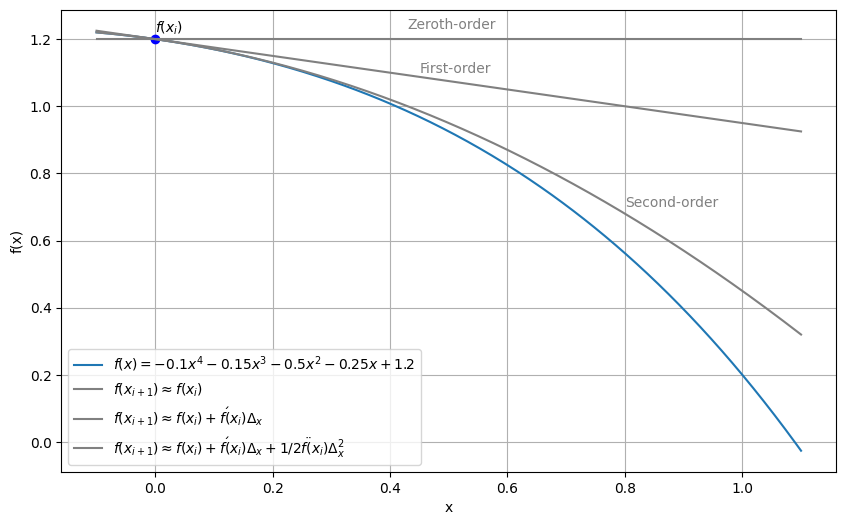

In [ ]:
# @title ##🧪 Sample Taylor Expansion
import numpy as np
import matplotlib.pyplot as plt

# true function
def f(x):
    return -0.1*x**4 - 0.15*x**3 - 0.5*x**2 - 0.25*x + 1.2
# derivative of true function
def dfdx(x):
    return -0.4*x**3 - 0.45*x**2 - 1.0*x - 0.25
# second derivative of true function
def d2fdx2(x):
    return -1.2*x**2 - 0.90*x - 1.0

x = np.linspace(-0.1, 1.1, 400) # Generate 400 points between -0.1 and 1.1
y = f(x)

plt.figure(figsize=(10, 6))
plt.plot(x, y, label=r'$f(x) = -0.1x^4 - 0.15x^3 - 0.5x^2 - 0.25x + 1.2$')

# label point about which to expand
plt.text(0, 1.22, r'$f(x_i)$')
plt.plot([0], [f(0)], 'bo')
plt.Circle((0, f(0)), 0.02, color='blue', fill=True)

# zeroth-order approximation
def f0(x,fx):
    return np.full(x.size,fx)

plt.plot(x, f0(x,f(0)), label=r'$f(x_{i+1}) \approx f(x_i)$', color='gray')
# add series label
plt.text(0.43, 1.23, 'Zeroth-order', color='gray')

# first-order approximation
def f1(x,fx,dfdx):
    return np.full(x.size,fx) + dfdx*(x-0)

plt.plot(x, f1(x,f(0),dfdx(0)), label=r'$f(x_{i+1}) \approx f(x_i) + f\'(x_i)\Delta_x$', color='gray')
# add series label
plt.text(0.45, 1.1, 'First-order', color='gray')

# second-order approximation
def f2(x,fx,dfdx, d2fdx2):
    return np.full(x.size,fx) + dfdx*(x-0) + 0.5*d2fdx2*(x-0)**2

plt.plot(x, f2(x,f(0),dfdx(0),d2fdx2(0)), label=r'$f(x_{i+1}) \approx f(x_i) + f\'(x_i)\Delta_x +1/2 f\"(x_i)\Delta^2_x$', color='gray')
# add series label
plt.text(0.8, 0.7, 'Second-order', color='gray')

plt.xlabel('x')
plt.ylabel('f(x)')
plt.grid(True)
plt.legend()
plt.show()

### 🔹 Taylor Series Expansion and Trunction Error

If we continue the process above we arrive at the following general expression for a Taylor Series of up *n*-th order.

\begin{eqnarray}
f(x_{i+1}) = f(x_i) +\frac{\mbox{d}f}{\mbox{d}x}(x_i)\Delta_x + \frac{1}{2!}\frac{\mbox{d}^2 f}{\mbox{d}x^2}(x_i)\Delta^2_x + \dots + \frac{1}{n!}\frac{\mbox{d}^n f}{\mbox{d}x^n}(x_i)\Delta^n_x + \epsilon_n, \tag{2.20}
\end{eqnarray}

where $\epsilon_n$ is the error introduced by the use of the expansion in place of the true function. From the *Sample Taylor Expansion* plot we can see that this error is proportional to the order $n$ of the expansion, hence the subscript *n* on the error term. The Taylor series is an infinite series, $n\rightarrow \infty$, which in practice needs to be truncated to a finite number of terms, $n$.

Logically, the error term, will be on the order of the $n+1$ term as these terms continue to get smaller with each $n$ and more closely approximate a **smooth** function. We will leave it to the mathematicians to prove that

\begin{equation}
\epsilon_n = \frac{1}{(n+1)!}\frac{\mbox{d}^{n+1}f}{\mbox{d}x^{n+1}}(\gamma)\Delta^{n+1}_x, \tag{2.21}
\end{equation}

where $\gamma$ corresponds to the gradient at some point between $x_i$ and $x_{i+1}$ (see Chapra & Clough (2022), *[Applied Numerical Methods with Python for Engineers and Scientists](https://www.mheducation.com/highered/product/applied-numerical-methods-with-python-for-engineers-and-scientists-chapra.html?viewOption=student)*, McGraw Hill).

In practice, we generally won't know the gradients at a point $\epsilon$. If we did, we probably wouldn't need to use the Taylor Series Approximation.

What we can do is use the principles of the Taylor series to understand that the **Truncation error** introduced by this method is on the order of the n+1 power of the stepsize between out data points, i.e.

\begin{equation}
\epsilon_n = \mathcal{O}(\Delta^{n+1}_x). \tag{2.22}
\end{equation}

This means that the error is proporsional to $\Delta^{n+1}_x$. If we increase the order of the approximation, $n$, and/or decrease the step $
\Delta_x$, the error will be reduced.

> ### 💬 Aside
> Increasing the order of a methods will always increase the accurracy in the absence of measurement noise. However, increasing the number of terms in a series and each additional multiplication and addition will result in more rounding errors and error propagation. In the case of noisely data and gradients, this acculated error may overwhelm the reduction in truncation error.  

## 📂 2.2.9 Errors in Approximating a Function

---

Consider the general case where we have a function of two or more variables,

\begin{equation}
y = f(x_1, x_2, \dots, x_n)
\end{equation}

As we have discussed, in most cases there will be an error in each variable, $x_i$, and therefore an error in $y$, i.e.

\begin{equation}
y + \epsilon_y= f(x_1+\epsilon_{x_1}, x_2+\epsilon_{x_2},\dots,x_n+\epsilon_{x_n})
\end{equation}

To understand the implications of this, it helps to expands the right-hand side of this expression as a *Taylor Series Expansion* around $x_1, x_2, \dots, x_n$, by the error terms $\epsilon_{x_1}, \epsilon_{x_2}, \dots ,\epsilon_{x_n}$. In fact let's make it a little easier and assume, for now, that we only have one variable $x_1$, such that

\begin{eqnarray}
y + \epsilon_y = f(x_1+\epsilon_{x_1}) \approx f(x_1) + \frac{\mbox{d}f}{\mbox{d}x_1}(x_1)\epsilon_{x_1}+\frac{1}{2}\frac{\mbox{d}^2 f}{\mbox{d}x^2_1}(x_1)\epsilon^2_{x_1} + \dots + \frac{1}{n!}\frac{\mbox{d}^n f}{\mbox{d}x^n_1}(x_1)\epsilon^n_{x_1}.
\end{eqnarray}

This is no different to the Taylor Series we had before in equation 2.20, expect now the point we are approximate the function at, in the $x_1$ direction is $x_1+\epsilon_{x_1}$.

A Taylor Series Expansion for a function of multiple variables in an expansion in each direction. To *first-order* this is similarly

\begin{eqnarray}
y + \epsilon_y = f(x_1+\epsilon_{x_1}, x_2 +\epsilon_{x_2}) \approx f(x_1,x_2) + \frac{\partial f}{\partial x_1}(x_1,x_2)\epsilon_{x_1}+\frac{\partial f}{\partial x_2}(x_1,x_2)\epsilon_{x_2}. \tag{2.23}
\end{eqnarray}
**Note:** We have replaced our derivatives with partial derivatives.


>### 📐 Higher-order terms of Multi-dimensional Taylor Series Expansion
>The higher order terms get a little more complex. Recall when we introduced the Taylor series we arrived at the second order terms by estimating the first derivative at the mid-point between some $x_i$ and $x_{i+1}$. Doing the same here where the point of the function we are estimating is offset in both the $x_1$ and $x_2$ directions, this means we need to account for changes in gradients in both directions. For instance, consider a first-order Taylor Series Expansion of $\partial f/\partial x_1$,
>
>\begin{eqnarray}
\frac{\partial f}{\partial x_1}(x_1+\epsilon_{x_1},x_2+\epsilon_{x_2}) &\approx& \frac{\partial f}{\partial x_1}(x_1,x_2)+ \frac{\partial }{\partial x_1}\left(\frac{\partial f}{\partial x_1}\right)(x_1,x_2)\epsilon_{x_1}+\frac{\partial }{\partial x_2}\left(\frac{\partial f}{\partial x_1}\right)(x_1,x_2)\epsilon_{x_2}\\
&\approx& \frac{\partial f}{\partial x_1}(x_1,x_2)+ \frac{\partial ^2 f}{\partial x^2_1}(x_1,x_2)\epsilon_{x_1}+\frac{\partial^2 f}{\partial x_1\partial x_2}(x_1,x_2)\epsilon_{x_2}
\end{eqnarray}
>
>Similarly, the first-order Taylor Series Expansion of $\partial f/\partial x_2$, is given by
>
>\begin{eqnarray}
\frac{\partial f}{\partial x_2}(x_1+\epsilon_{x_1},x_2+\epsilon_{x_2}) &\approx& \frac{\partial f}{\partial x_2}(x_1,x_2)+ \frac{\partial }{\partial x_1}\left(\frac{\partial f}{\partial x_2}\right)(x_1,x_2)\epsilon_{x_1}+\frac{\partial }{\partial x_2}\left(\frac{\partial f}{\partial x_2}\right)(x_1,x_2)\epsilon_{x_2}\\
&\approx& \frac{\partial f}{\partial x_2}(x_1,x_2)+ \frac{\partial^2 f}{\partial x^2_2}(x_1,x_2)\epsilon_{x_2}+\frac{\partial^2 f}{\partial x_1\partial x_2}(x_1,x_2)\epsilon_{x_1}
\end{eqnarray}
>
>Replacing the gradients in the first-order expansion of $y$ with the average of the gradient at $x_1,x_2$ and $x_1+\epsilon_{x_1}, x_1+\epsilon_{x_2}$, and subsituting in the expression above yields
>
>\begin{eqnarray}
y + \epsilon_y &\approx& f(x_1,x_2) + \frac{1}{2}\left(\frac{\partial f}{\partial x_1}(x_1,x_2)
+ \frac{\partial f}{\partial x_1}(x_1+\epsilon_{x_1},x_2+\epsilon_{x_2})\right)\epsilon_{x_1}+\frac{1}{2}\left(\frac{\partial f}{\partial x_2}(x_1,x_2)+\frac{\partial f}{\partial x_2}(x_1+\epsilon_{x_1},x_2+\epsilon_{x_2})\right)\epsilon_{x_2}\\
&\approx& f(x_1,x_2) + \frac{1}{2}\left(2\frac{\partial f}{\partial x_1}(x_1,x_2)
+ \frac{\partial ^2 f}{\partial x^2_1}(x_1,x_2)\epsilon_{x_1}+\frac{\partial ^2 f}{\partial x_1\partial x_2}(x_1,x_2)\epsilon_{x_2}      )\right)\epsilon_{x_1}+\frac{1}{2}\left(2\frac{\partial f}{\partial x_2}(x_1,x_2)+ \frac{\partial^2 f}{\partial x^2_2}(x_1,x_2)\epsilon_{x_2}+\frac{\partial^2 f}{\partial x_1\partial x_2}(x_1,x_2)\epsilon_{x_1}  )\right)\epsilon_{x_2}\\
&\approx& f(x_1,x_2) + \frac{\partial f}{\partial x_1}(x_1,x_2)\epsilon_{x_1} + \frac{\partial f}{\partial x_2}(x_1,x_2)\epsilon_{x_2} + \frac{1}{2}\frac{\partial^2 f}{\partial x^2_1}(x_1,x_2)\epsilon^2_{x_1} + \frac{1}{2}\frac{\partial^2 f}{\partial x^2_2}(x_1,x_2)\epsilon^2_{x_2} + \frac{\partial ^2 f}{\partial x_1\partial x_2}(x_1,x_2)\epsilon_{x_1}\epsilon_{x_2}.
\end{eqnarray}
>
>This multi-dimension second-order expansion therefore includes additional partial derivatives associated with change in gradiens along multiple directions.

Let's avoid the added complexity of these higher-order terms and come back to the *first-order* expansion of equation 2.23, This can be rearranged to express the difference between the true function and that based on non-exact inputs as

\begin{eqnarray}
\left| f(x_1,x_2)-f(x_1+\epsilon_{x_1}, x_2+\epsilon_{x_2})\right| \approx \frac{\partial f}{\partial x_1}(x_1,x_2)\epsilon_{x_1}+\frac{\partial f}{\partial x_2}(x_1,x_2)\epsilon_{x_2}
\end{eqnarray}

If we were to include, higher order terms of this Taylor Series Expansion, they would not cancel out, but would add to this, with each additional terms adding a finite, but smaller additional error.

We can therefore recognise that the error in evaluting the function $y$, i.e. $\epsilon_y$, will be of the order of the  first-order terms, hence for an function of $n$ inputs we can estimate the propagation of the error in each input to the error in the function as

\begin{equation}
\epsilon_y \approx \frac{\partial f}{\partial x_1}\epsilon_{x_1} + \frac{\partial f}{\partial x_2}\epsilon_{x_2} + \dots + \frac{\partial f}{\partial x_n}\epsilon_{x_n} \tag{2.24}
\end{equation}

>**What if f$(x_1, \dots, x_n)$ is a subtraction or multiplication like in section 2.1.5? Is this the same?**
>
>Maybe we can explore this in the practical problems.

## 📂 2.2.10 Order of Approximation

---

When discussing different algorithms or numerical approximations, it is common to use the term - *order of approxmation*.

For instance, we would say that a *first-order* Taylor Series approximates a function $f(x_i)$ with an order of approximation $\mathcal{O}(\Delta^2_x)$, meaning that the error is proportional to the square of the spacing between points.

> ### ⚠️ Point of note
> The order of the error doesn't tell you anything about the magnitude, which is this case would depend on the gradients of the specific function, but shows the sensitivity to grid spacing and the chosen method method.

For example, as per equation 2.22:
* a first-order Taylor Series has a **truncation error** on the order of $\mathcal{O}(\Delta^2_x)$,
* a fourth-order Taylor Series has an error on the order of $\mathcal{O}(\Delta^5_x)$.

**What happens if we halve the step size $\Delta_x$?**

Consider the ratio of the error with step-size $0.5\Delta_x$ to $\Delta_x$.  
\begin{equation}
\mbox{first-order: } \frac{\mathcal{O}\left((0.5\Delta_x)^2\right)}{\mathcal{O}(\left(\Delta_x)^2\right)} = \frac{1}{4}
\end{equation}

\begin{equation}
\mbox{first-order: } \frac{\mathcal{O}\left((0.5\Delta_x)^5\right)}{\mathcal{O}(\left(\Delta_x)^5\right)} = \frac{1}{32}
\end{equation}
The error for the first-order method will be quartered, while the error for the fourth-order method will be 32 times smaller.

## 📂 2.2.11 Total Numerical Error

---

So far we have discussed a number of different sources of error, including the error associated with having to *round-off* and approximate a numerical value (always required owing to the finite nature of a computers memory), the uncertainty of in a variable that might be associated with the input value or the results of a previous calculation, and the truncations that arise from a finite approximation to infinte mathematical functions.

>### ⚠️ Point of note
>Any numerical algorithm with a truncation will also have round-off error.
> Each time a value is rounded - we have to add this round-off error to the uncertainty of that variable.

As discussed in sections 2.2.10, we can reduce truncation errors by increasing the number of terms in a series. This requires additional numerical operations (+,-,$\times$,/), each of which bring an additional round-off error.

e.g. Consider the addition of a value, $x$, with an error $\epsilon_x$, added $n$ times. Based on propagation of errors via addition (section 2.2.6) the worst case error is the sum of the error in each value, i.e.
\begin{eqnarray}
\left| \sum_{i=1}^{n} x- \sum_{i=1}^{n} (x+\epsilon_x) \right| =n\left|\epsilon_x\right|
\end{eqnarray}

In increasing the number of terms in the series, we begin to accumulate additional rounding error.

> In engineering, we almost always end up with a compromise, be it cost and time vs precision, or in this case, the error of one type verses error of another!

### 🧪 Example of Total Error in a Series Approximation

It can be shown from a Taylor Series Expansion about x=0, that an exponential can be approximated by the following infinite series,

\begin{equation}
e^x = 1 + x + \frac{x^2}{2} + \frac{x^3}{3!} + \dots + \frac{x^n}{n!} \tag{2.25}
\end{equation}

For $n$ terms of the series, this has a truncation error of $\frac{x^{n+1}}{(n+1)!}$.

Estimating the impact of round-off error, is more difficult since, as we have seen, the error will propagate differently depending on the mathematical operation $(+,-,\times,/)$ and will therefore depend on the order in which they are applied.

> ### ⚠️ Point of note
> The order in which terms are evaluated can impact the propagation of errors and the accurracy of the final solution.

Consider $x^2$, if the error in $x$ is $\epsilon_x$, then

\begin{eqnarray}
|\epsilon_{x^2}| &=& |x'x'|\left(\left|\frac{\epsilon_{x}}{x'}\right| + \left|\frac{\epsilon_{x}}{x'}\right|\right)\\
|\epsilon_{x^2}| &=& 2|x'^2|\left|\frac{\epsilon_{x}}{x'}\right|\\
\left|\frac{\epsilon_{x^2}}{x'^2}\right| &=& 2\left|\frac{\epsilon_{x}}{x'}\right|
\end{eqnarray}
This comes from the *Absolute Error in Multiplication* as in section 2.2.6, $x'$ is the estimated value of $x$.

*Importantly*, this tells us that if $x'$ has a relative error of $\frac{\epsilon_{x}}{x'} = 10^{-7}$ as a floating point value, the error in the product will be larger that the $10^{-7}$. If this product is also stored to single precision, then the error associated with subsequent rounding-off of the stored product will be smaller than the error introduced by the multiplication. **Storing the value in its original precision won't add significant additional error**.

Representing the third power as the product of the square with $x$,
\begin{eqnarray}
|\epsilon_{x^3}| &=& |x'^2x'|\left(\left|\frac{\epsilon_{x^2}}{x'^2}\right| + \left|\frac{\epsilon_{x}}{x'}\right|\right)\\
|\epsilon_{x^3}| &=& |x'^3|\left(2\left|\frac{\epsilon_{x}}{x'}\right|+ \left|\frac{\epsilon_{x}}{x'}\right|\right)\\
\left|\frac{\epsilon_{x^3}}{x'^3}\right| &=& 3\left|\frac{\epsilon_{x}}{x'}\right|
\end{eqnarray}

From this we can extrapolate to say that the relative error for the product of $x$ with itself will be
\begin{eqnarray}
\left|\frac{\epsilon_{x^n}}{x'^n}\right| = n\left|\frac{\epsilon_{x}}{x'}\right| \tag{2.25a}
\end{eqnarray}

Consider the denominator $n!$. This factorial represents \begin{equation}
n! = \prod^n_{k=1} k,
\end{equation}
which for n = 3 is the production $3\times 2\times 1$. If, as in the present case, these remain small integers, this can be calculated exactly without roundoff. If the denominator has no error, then division has no impact on the relative error as from our expression for the *Absolute Error in Division*
\begin{eqnarray}
\left|\frac{\epsilon_{x^n/n!}}{x'^n/n!}\right| &=& \left(\left|\frac{\epsilon_{x^n}}{x'^2}\right|+\left|\frac{\epsilon_{n!}}{n!'}\right|\right)\\
&=& n\left|\frac{\epsilon_{x}}{x'}\right|, \tag{2.25b}
\end{eqnarray}
given $\epsilon_{n!} = 0$.

The 'worst case' error associated with the addition of each of these terms is simply the sum of the uncertainty in each term, hence if each term has an error as per Equation 2.25b, the error associated with the summation will be

\begin{eqnarray}
|\epsilon_{e^x}|_{round} &=& \left|\frac{\epsilon_{x}}{x'}\right|x'+2\left|\frac{\epsilon_{x}}{x'}\right|(x'^2/2!)+\dots+n\left|\frac{\epsilon_{x}}{x'}\right|(x'^n/n!)\\
|\epsilon_{e^x}|_{round} &=& \left|\frac{\epsilon_{x}}{x'}\right|x'+2\left|\frac{\epsilon_{x}}{x'}\right|(x'^2/2!)+\dots+\left|\frac{\epsilon_{x}}{x'}\right|(x'^n/(n-1)!) \tag{2.25c}
\end{eqnarray}

If we assume all terms are 32-bit floats with a relative error of $10^{-7}$ or $10^{-5}\%$, then for the evaluation of $x = 1$ the error for equation 2.25 becomes,
\begin{eqnarray}
\mbox{truncation error } &=& \frac{1}{(n+1)!}\\
\mbox{rounding error: }&\approx&\left|\frac{\epsilon_{x}}{x'}\right|\approx 1\times 10^{-7}
\end{eqnarray}

In this case the rounding error remains small as powers of 1 in equation 2.25c, i.e. $x'^n$ for $x=1$ do not grow. For small values of $n$, the truncation will be much larger than the rounding error, with cross-over at $n \approx 10$. At larger value of $x$, the round-off will be more significant than in this case.


**Infact, computers and calculators use approximations like this to minimise error and speed-up calculations.**

Let's get our AI to generate a code for this to test and help demonstrate how this error changes.


### 🗣️ AI Prompts
> Prompt Gemini with: "provide a Python example of truncation error versus round-off error in a Taylor series approximation of e^x, plotting trunctation error and round-off error for a 32-bit float as a function of n terms".

### 🧠 AI Output
> The output was modified into the form shown below in the code cell. This included changes to the caption and inclusion as a form cell to avoid cluttering the notebook with the code itself and instead allow us to focus on the resulting errors.


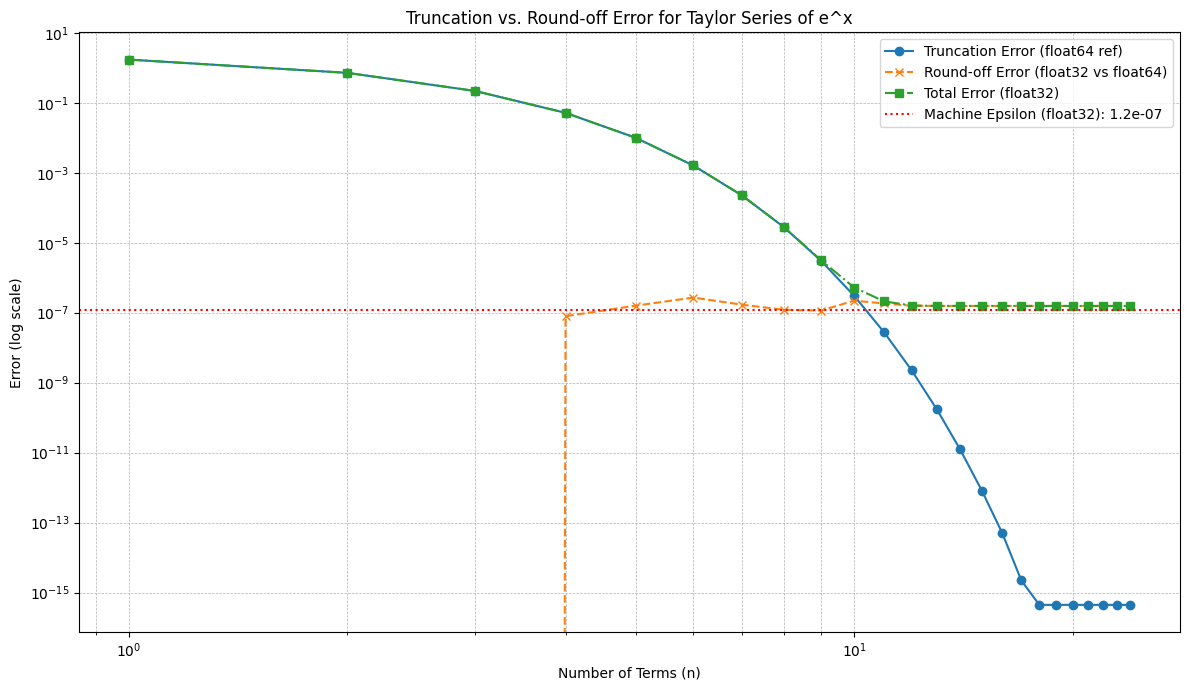

In [ ]:
# @title Error in Taylor Series Expansion of e^x for x = 1
import math
import numpy as np
import matplotlib.pyplot as plt

def taylor_exp(x, n_terms, dtype=np.float64):
    """Calculates e^x using Taylor series up to n_terms, with specified dtype."""
    result = dtype(0.0)
    term = dtype(1.0)
    # Loop up to n_terms - 1 because the first term is for i=0
    for i in range(n_terms):
        result += term
        # Ensure x and (i+1) are also of the correct dtype for calculation
        # term x^i/i! is held from last iteration and multilied by x/i+1 each loop
        term = term * dtype(x) / dtype(i + 1)
    return result

x_value = 1.0  # Value for x in e^x
true_exp_x = math.exp(x_value)

# Define a range of n_terms to test
n_terms_range = np.arange(1, 25)

truncation_errors = []
round_off_errors = []
total_errors = []

for n_terms in n_terms_range:
    # Calculate approximation using float64 for high precision reference
    approx_float64 = taylor_exp(x_value, n_terms, np.float64)

    # Calculate approximation using float32 to observe round-off
    approx_float32 = taylor_exp(x_value, n_terms, np.float32)

    # Truncation error (how far from true value, assuming float64 is ideal)
    truncation_errors.append(abs(true_exp_x - approx_float64))

    # Round-off error (difference between float64 and float32 approximation)
    # This isolates the error introduced by the limited precision of float32 arithmetic
    round_off_errors.append(abs(approx_float64 - approx_float32))

    # Total error - assuming float64 is ideal
    total_errors.append(abs(true_exp_x - approx_float64)+abs(approx_float64 - approx_float32))

# Plotting the errors
plt.figure(figsize=(12, 7))
plt.loglog(n_terms_range, truncation_errors, label='Truncation Error (float64 ref)', marker='o', linestyle='-')
plt.loglog(n_terms_range, round_off_errors, label='Round-off Error (float32 vs float64)', marker='x', linestyle='--')
plt.loglog(n_terms_range, total_errors, label='Total Error (float32)', marker='s', linestyle='-.')

# Add a line representing machine epsilon for float32
machine_epsilon_float32 = np.finfo(np.float32).eps
plt.axhline(y=machine_epsilon_float32, color='r', linestyle=':', label=f'Machine Epsilon (float32): {machine_epsilon_float32:.1e}')

plt.xlabel('Number of Terms (n)')
plt.ylabel('Error (log scale)')
plt.title('Truncation vs. Round-off Error for Taylor Series of e^x')
plt.legend()
plt.grid(True, which='both', linestyle='--', linewidth=0.5)
#plt.xticks(n_terms_range)
plt.tight_layout()
plt.show()

#### Explanation of the Plot:

*   **Truncation Error (blue line)**: This error generally decreases as the number of terms (`n_terms`) increases. This is because adding more terms makes the Taylor series a better approximation of the true `e^x` function. For very small `n_terms`, it dominates the total error.
*   **Round-off Error (orange line)**: This error shows the difference in the calculated value when using `float32` (single-precision) compared to `float64` (double-precision). Initially, as `n_terms` increases, the round-off error might be small or fluctuate. However, as more terms are added, and especially after the truncation error becomes very small, the accumulation of tiny errors from `float32` arithmetic can cause the round-off error to grow or become more prominent. Eventually, it will hit a floor determined by the machine epsilon of `float32`.
*   **Machine Epsilon (red dashed line)**: This horizontal line represents the smallest number that, when added to 1, yields a result greater than 1 using `float32` precision. It's a fundamental limit of floating-point arithmetic. The round-off error generally cannot go significantly below this value because `float32` simply cannot represent numbers with higher precision.

This plot visually demonstrates the trade-off: increasing `n_terms` reduces truncation error, but eventually, round-off error becomes the limiting factor, especially for lower-precision data types like `float32`.

So, would there be any point to using 15 terms to evaluate $e^x$?